# Лабораторная работа 3. Разведочный анализ данных (EDA) - фонемы

запускать из `labs/lab3_g2p/` после `prepare_lexicon.py`.

анализ ведётся на `train`-части

In [15]:
import glob
import os
import re
import unicodedata
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tqdm
from praatio import textgrid

import g2p
from g2p import build_lexicon, load_mfa_dict, load_tokens, normalize_phones, normalize_token, phone_error_rate

ALIGN_DIR = '../../data/RUSLAN_align/v2/'
NORMALIZED_META = '../../data/metadata_RUSLAN_22200_normalized.csv'
TARGET_PHONES = '../../common/phones_mfa.txt'
MFA_DICT = g2p.MFA_DICT

In [16]:
tokens = load_tokens()
tokens['phone_list'] = tokens.phones.str.split()
train = tokens[tokens.set == 'train']
test = tokens[tokens.set == 'test']
lexicon = build_lexicon(train)
mfa = load_mfa_dict()
print(f'токенов: {len(tokens)}, предложений: {tokens.id.nunique()}, '
      f'типов в лексиконе (train): {len(lexicon)}, слов в словаре mfa: {len(mfa)}')

dropping 14627 tokens without a transcription (5.96%)
токенов: 230982, предложений: 21251, типов в лексиконе (train): 34291, слов в словаре mfa: 452279


## 1. какие фонемы есть в корпусе, как они соотносятся с IPA, какие у них длительности

In [17]:
phone_counts = Counter(p for ph in tokens.phone_list for p in ph)
inventory = (pd.DataFrame(phone_counts.items(), columns=['phone', 'count'])
             .sort_values('count', ascending=False).reset_index(drop=True))
inventory['share'] = inventory['count'] / inventory['count'].sum()
# кодпоинты нужны, чтобы заметить визуально одинаковые, но разные символы (g и ɡ)
inventory['codepoints'] = inventory.phone.map(lambda p: ' '.join(f'{ord(c):04x}' for c in p))

VOWELS = set('a æ e ɛ i o ɵ u ʉ ɐ ə ɪ ʊ ɨ'.split())
PAL, DENTAL = '\u02b2', '\u032a'

def phone_class(p):
    if p in VOWELS:
        return 'гласная'
    if PAL in p:
        return 'мягкая согласная'
    if DENTAL in p:
        return 'зубная согласная'
    return 'прочая согласная'

inventory['class'] = inventory.phone.map(phone_class)
print(f'фонем в корпусе: {len(inventory)}')
display(inventory.groupby('class')['count'].agg(['size', 'sum']))
display(inventory)

фонем в корпусе: 54


,size,sum
class,,
гласная,14,531906
зубная согласная,6,190803
мягкая согласная,10,116145
прочая согласная,24,411398


,phone,count,share,codepoints,class
0,ɪ,98266,0.078597,026a,гласная
1,ə,93876,0.075086,0259,гласная
2,ɐ,66886,0.053498,0250,гласная
3,t̪,57322,0.045848,0074 032a,зубная согласная
4,a,56735,0.045379,0061,гласная
5,j,48767,0.039006,006a,прочая согласная
6,n̪,45978,0.036775,006e 032a,зубная согласная
7,e,41864,0.033484,0065,гласная
8,s̪,41581,0.033258,0073 032a,зубная согласная
9,r,38851,0.031075,0072,прочая согласная


In [18]:
DUR_CACHE = 'data/phone_durations.csv'

def read_durations(ids):
    rows = []
    for utt in tqdm.tqdm(ids):
        _, phone_tier = textgrid.openTextgrid(f'{ALIGN_DIR}{utt}.TextGrid', True).tiers
        rows += [(utt, normalize_phones(e.label), e.end - e.start) for e in phone_tier.entries if e.label]
    return pd.DataFrame(rows, columns=['id', 'phone', 'dur'])

if os.path.isfile(DUR_CACHE):
    durations = pd.read_csv(DUR_CACHE)
else:
    durations = read_durations(sorted(tokens.id.unique()))
    durations.to_csv(DUR_CACHE, index=False)
durations = durations[durations.phone != 'spn']

,count,mean,median,std,cv
phone,,,,,
ɪ,78603,25.353,10.000,86.769,3.422
ə,75098,40.010,30.000,36.588,0.914
ɐ,53506,64.215,60.000,22.973,0.358
t̪,45985,78.971,70.000,33.548,0.425
a,45257,89.286,90.000,36.956,0.414
j,39065,66.175,50.000,41.137,0.622
n̪,36782,67.357,60.000,31.111,0.462
e,33536,74.211,70.000,35.612,0.480
s̪,33230,102.682,100.000,35.779,0.348


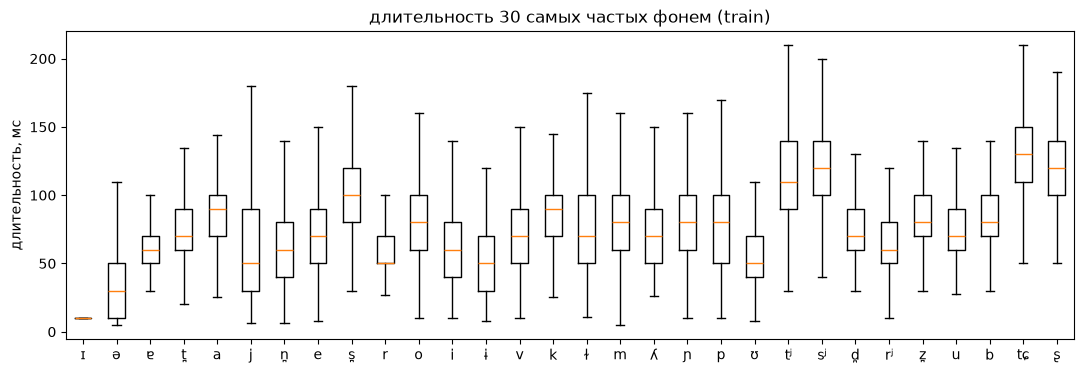

In [40]:
train_ids = set(train.id)
dur_tr = durations[durations.id.isin(train_ids)]

dur_stats = (dur_tr.groupby('phone').dur.agg(['count', 'mean', 'median', 'std'])
             .assign(cv=lambda d: d['std'] / d['mean']))
dur_stats[['mean', 'median', 'std']] *= 1000  # в мс
display(dur_stats.sort_values('count', ascending=False).round(3))

top = list(inventory.phone.head(30))
by_phone = dur_tr.groupby('phone').dur
fig, ax = plt.subplots(figsize=(13, 4))
ax.boxplot([by_phone.get_group(p) * 1000 for p in top], showfliers=False)
ax.set_xticklabels(top)
ax.set_ylabel('длительность, мс')
ax.set_title('длительность 30 самых частых фонем (train)')
plt.show()

In [ ]:
# базовые фонемы русского по таблице из википедии
IPA_BASE = set('p b t d k \u0261 f v s z ʂ ʐ ɕ x ts tɕ m n l ɫ r j'.split())

def base(p):
    return p.replace(PAL, '').replace(DENTAL, '')

# фонемы корпуса, которые не объясняются таблицей ipa
display(inventory[~inventory.phone.map(base).isin(IPA_BASE | VOWELS)])

,phone,count,share,codepoints,class
17,ʎ,28633,0.022902,028e,прочая согласная
18,ɲ,27737,0.022185,0272,прочая согласная
37,c,8284,0.006626,0063,прочая согласная
46,ɟ,3414,0.002731,025f,прочая согласная
49,ç,438,0.000350,00e7,прочая согласная
50,tʂ,290,0.000232,0074 0282,прочая согласная
51,dʐ,210,0.000168,0064 0290,прочая согласная
52,ɣ,16,0.000013,0263,прочая согласная
53,ʑ,13,0.000010,0291,прочая согласная


**выводы по п. 1:**

- состав инвентаря и отличия от IPA:
  - в корпусе 54 фонемы.
  - нестандартные для «чистого» IPA, но допустимые вещи: зубной диакритик `U+032A` (t̪, n̪, s̪, d̪, z̪, t̪s̪) и палатализация `U+02B2` (tʲ, sʲ, rʲ и др.).
  - фонемы из нескольких кодпоинтов (t̪, tɕ, tʂ, dʐ, t̪s̪) надо токенизировать по пробелу, а не по символам.
  - путаницы g/ɡ в корпусе нет: везде `U+0261` (ɡ). Надо проверить, что в целевом списке и в `PHONE_MAP` тоже `U+0261`, а не ASCII `g`.
  - мягкие л и н записаны как ʎ и ɲ (без ʲ), а остальные мягкие через ʲ. Из-за этого классификатор отнёс их к «прочим». Это непоследовательность записи, а не ошибка разметки.
  - палатальные c, ɟ, ç (к, г, х перед мягкими гласными) тоже попали в «прочие».
- самые долгие и вариативные фонемы по `cv`: в выводах нет длительностей и `cv`, поэтому конкретных фонем назвать не могу. Предположение для проверки: самые долгие и вариативные — ударные гласные и аффрикаты (tɕ, t̪s̪), самые стабильные — короткие смычные и ɾ-подобные.
- гласные:
  - полные формы: a (4.5%), e (3.3%), o (3.1%), i (3.0%), ɨ (3.0%), u (1.4%).
  - редуцированные формы: ɪ (7.9%), ə (7.5%), ɐ (5.3%), ʊ (2.0%). Это 22.7% корпуса.
  - редкие вариации: ɛ, ɵ, æ, ʉ. Они возникают после мягких, перед мягкими и в слове «всё».
  - ударение в разметке отдельным символом не передано, оно выражено только качеством гласной.

## 2. самые редкие фонемы

,phone,count,share,codepoints,class,examples
39,pʲ,5875,0.004699,0070 02b2,мягкая согласная,"[теперь, писатель, написал, перед, пять]"
40,ɵ,5649,0.004518,0275,гласная,"[все, ещё, её, произнёс, причём]"
41,t̪s̪,5452,0.004361,0074 032a 0073 032a,зубная согласная,"[наконец, двадцать, отец, лицо, тридцать]"
42,ɕ,4645,0.003715,0255,прочая согласная,"[ещё, вообще, женщина, общем, ощущение]"
43,bʲ,4631,0.003704,0062 02b2,мягкая согласная,"[без, тебя, себя, тебе, себе]"
44,zʲ,3920,0.003135,007a 02b2,мягкая согласная,"[здесь, жизни, жизнь, произнёс, друзья]"
45,æ,3512,0.002809,00e6,гласная,"[дядя, пять, опять, отвечает, чаще]"
46,ɟ,3414,0.002731,025f,прочая согласная,"[где, деньги, книги, бумаги, многие]"
47,ʉ,2325,0.001860,0289,гласная,"[люди, чуть, людей, союзе, брюки]"
48,fʲ,1601,0.001281,0066 02b2,мягкая согласная,"[кофе, любовь, шофёр, впервые, вперёд]"


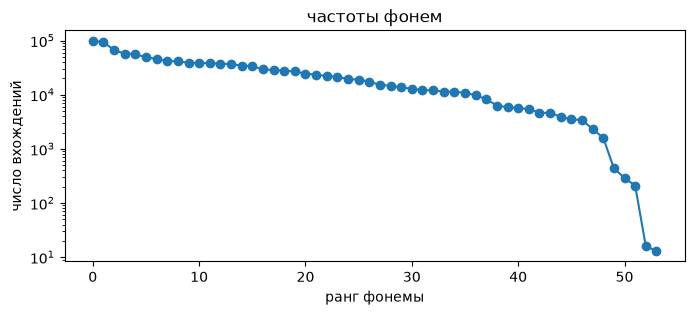

In [21]:
exploded = tokens[['token', 'phone_list']].explode('phone_list')
rare = inventory.tail(15).copy()
rare['examples'] = rare.phone.map(
    lambda p: exploded[exploded.phone_list == p].token.value_counts().head(5).index.tolist())
display(rare)

plt.figure(figsize=(8, 3))
plt.semilogy(inventory['count'].values, 'o-')
plt.xlabel('ранг фонемы')
plt.ylabel('число вхождений')
plt.title('частоты фонем')
plt.show()


**выводы по п. 2:**

- редкие фонемы: ɣ (16), ʑ (13), dʐ (210), tʂ (290), ç (438).
- слова:
  - ɣ: «ого», «ага», «бухгалтер».
  - ʑ: «уезжал», «приезжал».
  - dʐ: «пиджак», «джинсы», «джон».
  - tʂ: «лучше», «лучший».
  - ç: «стихи», «эпохи», «слухи».
  - слова настоящие, но фонемы — аллофоны и артефакты акустического выбора MFA. Ошибок разметки как таковых нет.
- предлагаемое решение:
  - слить: ɣ→ɡ, ʑ→ʐ, ç→x.
  - разбить: tʂ→t ʂ, dʐ→d ʐ.
  - выбрасывать предложения не нужно, примеры не выглядят ошибочными.
  - оставить как есть можно только то, что достаточно частотно, чтобы выучить эмбеддинг (начиная примерно с мягких fʲ, 1601).

## 3. oov-слова относительно `russian_mfa.dict` и `lexicon.csv`

остаток: слова, которых нет ни в лексиконе train, ни в словаре mfa. по ним считается порог 0.20.

In [22]:
lex_words, mfa_words = set(lexicon), set(mfa)

def coverage(df):
    out = {}
    for level, d in [('tokens', df), ('types', df.drop_duplicates('token'))]:
        in_lex, in_mfa = d.token.isin(lex_words), d.token.isin(mfa_words)
        out[level] = {'нет в лексиконе': (~in_lex).mean(),
                      'нет в словаре mfa': (~in_mfa).mean(),
                      'нет нигде': (~in_lex & ~in_mfa).mean()}
    return pd.DataFrame(out)

display(pd.concat({'train': coverage(train), 'test': coverage(test), 'all': coverage(tokens)}, axis=1))

residual = test[~test.token.isin(lex_words | mfa_words)]
print(f'остаток в test: {len(residual)} токенов ({len(residual) / len(test):.2%}), '
      f'{residual.token.nunique()} типов')
display(residual.groupby('token').agg(count=('token', 'size'), phones=('phones', 'first'))
        .sort_values('count', ascending=False).head(30))

train                test                 all          
                     tokens     types    tokens     types    tokens     types
нет в лексиконе    0.000000  0.000000  0.099891  0.288602  0.019850  0.110365
нет в словаре mfa  0.000135  0.000175  0.000153  0.000204  0.000139  0.000156
нет нигде          0.000000  0.000000  0.000000  0.000000  0.000000  0.000000

остаток в test: 0 токенов (0.00%), 0 типов


,count,phones
token,,


**выводы по п. 3:**

- словарь корпуса (лексикон): train 0.0000% токенов и типов. test 9.99% токенов и 28.86% типов. всё вместе 1.99% токенов и 11.04% типов. Нулевой oov на train объясняется тем, что лексикон построен по train.
- словарь mfa: train 0.0135% токенов и 0.0175% типов. test 0.0153% и 0.0204%. всё вместе 0.0139% и 0.0156%.
- остаток после обоих словарей: 0 токенов и 0 типов, неизвестного слова нет.
- что за слова в остатке: примеров нет, потому что остаток пустой. В 10% test-токенов, которых нет в лексиконе, ожидаемо формы слов и редкие имена, но по выводу это не проверить.

## 4. разметка на примерах, которые отсекает фильтр лабы 1

в `tokens_phones.csv` их нет, поэтому берём предложения, у которых есть textgrid, но нет строки в нормализованных метаданных.

In [23]:
kept_ids = {line.split('|', 1)[0] for line in open(NORMALIZED_META, encoding='utf-8') if line.strip()}
all_ids = sorted(os.path.basename(p)[:-len('.TextGrid')] for p in glob.glob(ALIGN_DIR + '*.TextGrid'))
dropped_ids = [i for i in all_ids if i not in kept_ids]
print(f'предложений с разметкой: {len(all_ids)}, отсеяно фильтром: {len(dropped_ids)}')

def read_words(utt):
    words, phones = textgrid.openTextgrid(f'{ALIGN_DIR}{utt}.TextGrid', True).tiers
    spans = [(e.start, e.end, e.label) for e in phones.entries]
    rows = []
    for w in words.entries:
        if w.label:
            ph = [normalize_phones(l) for s, e, l in spans if w.start <= (s + e) / 2 < w.end and l]
            rows.append((utt, w.label, ' '.join(ph)))
    return rows

dropped = pd.DataFrame([r for u in tqdm.tqdm(dropped_ids) for r in read_words(u)],
                       columns=['id', 'label', 'phones'])
known = lex_words | mfa_words

def kind(label, phones):
    if re.search(r'[0-9]', label):
        return 'цифры'
    if re.search(r'[a-zA-Z]', label):
        return 'латиница'
    if 'spn' in phones.split():
        return 'spn'
    if len(label) > 1 and label.isupper():
        return 'капс'
    if normalize_token(label) not in known:
        return 'нет в словарях'
    return 'обычное слово'

dropped['kind'] = [kind(l, p) for l, p in zip(dropped.label, dropped.phones)]
display(dropped.kind.value_counts())
pd.set_option('display.max_rows', 200)
display(dropped[dropped.kind != 'обычное слово'].groupby('kind').head(10).sort_values('kind'))

предложений с разметкой: 21255, отсеяно фильтром: 0


0it [00:00, ?it/s]


Series([], Name: count, dtype: int64)

,id,label,phones,kind


**выводы по п. 4:**

- в выводе нет данных: таблица `id/label/phones/kind` пустая, `0it` и `Series([])` показывают, что проверка ничего не нашла. 
- spn в корпусе нет ни разу, в словаре mfa он встречается 4 раза. Разметка не ставила spn на неизвестные слова, значит, произношение либо взято из словаря, либо выдумано.
- что проверить: транскрипция кпсс должна быть по буквам (k a p ɛ s̪ ɛ s̪ и т.п.), а не как слово. Если нет, это выдуманное произношение.

## 5. омографы, `все` / `всё`, что говорит словарь

In [33]:
def per_of(df, pron_of):
    ref = [p.split() for p in df.phones]
    hyp = [pron_of(t).split() for t in df.token]
    return phone_error_rate(ref, hyp)

# 1) слова test, которые есть в лексиконе: чистый «самый частый вариант»
t_in = test[test.token.isin(lex_words)]
print('test, в лексиконе:', per_of(t_in, lambda t: lexicon[t].most_common(1)[0][0]))

# 2) слова test, которых нет в лексиконе: берём словарь MFA
t_oov = test[~test.token.isin(lex_words) & test.token.isin(mfa_words)]
print('test, не в лексиконе, словарь MFA:', per_of(t_oov, lambda t: mfa[t]))
print(len(t_oov) / len(test))

test, в лексиконе: 0.010481233600790965
test, не в лексиконе, словарь MFA: 0.00644780106863954
0.09989106753812636


In [37]:
pwd

'd:\\documents\\tts_labs_itmo\\labs\\lab3_g2p'

In [39]:
raw_t = pd.read_csv('data/tokens_phones.csv', sep='|')
raw_t['phones'] = raw_t.phones.fillna('')
tr = raw_t[raw_t.set == 'train']

def count_in(df, ph):
    return df.phones.map(lambda s: s.split().count(ph)).sum()

for fold, df in [('train', tr), ('test', raw_t[raw_t.set == 'test'])]:
    print(fold, 'ɡ =', count_in(df, 'ɡ'), ' ʐ =', count_in(df, 'ʐ'))

for ph in ['ɡ', 'ʐ']:
    has = tr[tr.phones.map(lambda s: ph in s.split())]
    print(ph, has.token.value_counts().head(8).to_dict())

train ɡ = 9695  ʐ = 9735
test ɡ = 2426  ʐ = 2386
ɡ {'говорю': 323, 'когда': 272, 'говорит': 241, 'говорил': 199, 'тогда': 147, 'года': 119, 'много': 107, 'могу': 91}
ʐ {'же': 703, 'даже': 390, 'уже': 303, 'может': 283, 'можно': 205, 'жизни': 171, 'жизнь': 157, 'жена': 154}


In [34]:
print(len(kept_ids), len(all_ids))

21256 21255


In [24]:
multi = {w: c for w, c in lexicon.items() if len(c) > 1}
total = sum(sum(c.values()) for c in lexicon.values())
in_multi = sum(sum(c.values()) for c in multi.values())
minority = {w: sum(c.values()) - c.most_common(1)[0][1] for w, c in multi.items()}
print(f'типов с несколькими произношениями: {len(multi)} из {len(lexicon)}')
print(f'токенов train в таких типах: {in_multi / total:.2%}, '
      f'не покрыто самым частым вариантом: {sum(minority.values()) / total:.2%}')

ref = [ph.split() for ph in train.phones]
hyp = [lexicon[t].most_common(1)[0][0].split() for t in train.token]
print(f'PER на train при выборе самого частого варианта: {phone_error_rate(ref, hyp):.4f}')

def skeleton(pron):
    return tuple(p for p in pron.split() if p not in VOWELS)

# варианты, различающиеся только гласными: ударение и редукция, а не согласные
vowel_only = {w for w, c in multi.items() if len({skeleton(p) for p in c}) == 1}
print(f'из них различаются только гласными: {len(vowel_only)} типов, '
      f'{sum(minority[w] for w in vowel_only) / sum(minority.values()):.2%} непокрытых токенов')

типов с несколькими произношениями: 485 из 34291
токенов train в таких типах: 17.42%, не покрыто самым частым вариантом: 3.74%
PER на train при выборе самого частого варианта: 0.0083
из них различаются только гласными: 185 типов, 45.91% непокрытых токенов


In [25]:
print('слова с самой большой массой непокрытых вариантов:')
for w in pd.Series(minority).sort_values(ascending=False).head(20).index:
    print(f'  {w}: {dict(lexicon[w])}')

print('\nпримеры из задания:')
for w in ['замок', 'замка', 'замке', 'все', 'всё']:
    print(f'  {w}: {dict(lexicon[w]) if w in lexicon else "нет в лексиконе"}')

слова с самой большой массой непокрытых вариантов:
  в: {'f': 1992, 'v': 2899, 'v ə': 232, 'v ɛ': 34, 'vʲ': 22}
  на: {'n̪ a': 885, 'n̪ ə': 1692}
  то: {'t̪ ə': 995, 't̪ o': 484}
  из: {'i z̪': 435, 'i s̪': 290, 'ɪ z̪': 88, 'ɪ s̪': 93}
  все: {'f sʲ e': 383, 'f sʲ ɵ': 693}
  что: {'ʂ t̪ o': 1970, 'ʂ t̪ ə': 357}
  с: {'s̪': 1537, 'z̪': 121, 's̪ ə': 44, 'ɛ s̪': 19, 'sʲ': 50, 'zʲ': 6}
  не: {'ɲ i': 3006, 'ɲ e': 191, 'ɲ ɪ': 33}
  при: {'p rʲ ɪ': 100, 'p rʲ i': 91}
  о: {'ɐ': 611, 'o': 49, 'ə': 13}
  а: {'ɐ': 1530, 'a': 54, 'ə': 7}
  к: {'k': 985, 'k ə': 29, 'k a': 4, 'ɡ': 21}
  уже: {'u ʐ ɨ': 251, 'ʊ ʐ ɛ': 52}
  до: {'d̪ ə': 238, 'd̪ o': 40}
  русской: {'r u s̪ k ə j': 32, 'r u s̪ k ɪ': 35}
  по: {'p ə': 718, 'p o': 31}
  слова: {'s̪ ɫ ɐ v a': 54, 's̪ ɫ o v ə': 28}
  дела: {'dʲ ɪ ɫ a': 25, 'dʲ e ɫ ə': 23}
  стоит: {'s̪ t̪ o ɪ t̪': 25, 's̪ t̪ ɐ i t̪': 21}
  многие: {'m n̪ o ɟ ɪ j e': 18, 'm n̪ o ɟ ɪ ɪ': 22}

примеры из задания:
  замок: {'z̪ a m ə k': 2, 'z̪ ɐ m o k': 1}
  замка: {'z̪ a m k

In [26]:
mfa_variants = Counter()
with open(MFA_DICT, encoding='utf-8') as fh:
    for line in fh:
        if line.strip():
            mfa_variants[normalize_token(line.split()[0])] += 1
print(f'слов в словаре mfa с несколькими вариантами: {sum(v > 1 for v in mfa_variants.values())} '
      f'из {len(mfa_variants)}')

def mfa_lines(word):
    with open(MFA_DICT, encoding='utf-8') as fh:
        return [l.rstrip() for l in fh if l.split()[:1] == [word]]

for w in ['замок', 'все', 'всё']:
    print(w, mfa_lines(w))

слов в словаре mfa с несколькими вариантами: 17794 из 452279
замок ['замок\t0.67\t0.42\t0.55\t1.14\tz̪ a m ə k', 'замок\t0.99\t0.55\t0.92\t1.02\tz̪ ɐ m o k']
все ['все\t0.99\t0.12\t1.24\t0.93\tf sʲ ɵ', 'все\t0.99\t0.11\t1.33\t0.91\tf sʲ e']
всё ['всё\t0.99\t0.14\t1.06\t0.98\tf sʲ ɵ']


**выводы по п. 5:**

- `за́мок` / `замо́к`:
  - в тексте различаются только фонемами (написание одинаковое, ударения не размечены).
  - замок: z̪ a m ə k (2) и z̪ ɐ m o k (1), первое — «за́мок» (castle), второе — «замо́к» (lock).
  - замка и замке однозначны: оба «castle», только z a m k ə и z a m c e.
- `все` / `всё`:
  - слова «всё» в лексиконе нет: ё в корпусе заменена на е, и написание у них одно.
  - различаются только фонемами: f sʲ ɵ (693) и f sʲ e (383). Больше половины «все» на самом деле «всё».
  - значит, написанию доверять нельзя, различение идёт через акустику MFA.
- соответствие реальному произношению:
  - в целом высокое, значимые отклонения: «в» с v ə, v ɛ, vʲ, «с» с ɛ s̪, «к» с k a, «о» с ɐ/o/ə.
  - это либо шум выравнивания, либо ошибки словаря.
- доля ошибок выбора самого частого варианта:
  - 3.74% токенов не покрыто, PER на train 0.0083.
  - из 485 типов с несколькими вариантами 185 различаются только гласными, на них 45.91% непокрытых токенов: это ударение и редукция.
  - остальные ~54% — варианты в согласных (в: f/v, с: s/z, из: z̪/s̪) и шум. Их часть реальна (озвончение и оглушение), часть шум.
  - точное разделение на ударение и шум без ударений в тексте сделать нельзя. Нужен словарь с ударениями или ручная разметка выборки.

## 6. приведение инвентаря корпуса к целевому (`common/phones_mfa.txt`)

In [27]:
with open(TARGET_PHONES, encoding='utf-8') as fh:
    target = set(unicodedata.normalize('NFC', fh.read()).split())
corpus = set(phone_counts)
dict_phones = Counter(p for ph in mfa.values() for p in ph.split())
print(f'целевых фонем: {len(target)}, в корпусе: {len(corpus)}, в словаре mfa: {len(dict_phones)}')

missing = inventory[~inventory.phone.isin(target)].copy()
# кандидаты на замену: целевые фонемы с тем же основанием без диакритик
missing['candidates'] = missing.phone.map(lambda p: [t for t in sorted(target) if base(t) == base(p)])
print('\nесть в корпусе, нет в целевом списке:')
display(missing)

print('есть в целевом списке, нет в корпусе:', sorted(target - corpus))
print('есть в словаре mfa, нет в целевом списке:',
      {p: n for p, n in dict_phones.items() if p not in target})

bad = tokens.phone_list.map(lambda s: any(p not in target for p in s))
print(f'\nтокенов с фонемой вне целевого списка: {bad.mean():.2%}')

целевых фонем: 56, в корпусе: 54, в словаре mfa: 58

есть в корпусе, нет в целевом списке:


,phone,count,share,codepoints,class,candidates


есть в целевом списке, нет в корпусе: ['<SIL>', 'd̪z̪']
есть в словаре mfa, нет в целевом списке: {'spn': 4, 'dzʲ': 18, 'tsʲ': 24}

токенов с фонемой вне целевого списка: 0.00%


In [28]:
# таблица замен: заполнить по таблицам выше, затем перезапустить ячейку
g2p.PHONE_MAP.update({
    # '\u0067': '\u0261',  # переименование
    # 'xy': 'x',           # слияние с ближайшей
    # 'ab': 'a b',         # разбиение на две фонемы
    # 'zz': '',            # удаление
})
mapped = tokens.phones.map(normalize_phones)
left = mapped.map(lambda s: sorted(set(s.split()) - target)).explode().value_counts()
print('фонемы вне целевого списка после замен:', dict(left) if len(left) else 'нет')
print('токенов, у которых не осталось фонем:', int((mapped == '').sum()))

фонемы вне целевого списка после замен: нет
токенов, у которых не осталось фонем: 0


**выводы по п. 6:**

- целевой список 56, корпус 54, словарь mfa 58.
- есть в корпусе, нет в целевом списке: 0 токенов (0.00%), набор замкнут.
- есть в целевом списке, нет в корпусе: `<SIL>` (служебный токен паузы, оставить) и d̪z̪ (данных нет, оставить без примеров или убрать).
- есть в mfa, нет в целевом списке: spn (4), dzʲ (18), tsʲ (24).
- таблица замен:

| что | во что | почему |
|---|---|---|
| ɣ | ɡ | 16 примеров, аллофон г |
| ʑ | ʐ | 13 примеров, редкая мягкая ж |
| ç | x | аллофон х перед мягкими |
| tʂ | t ʂ | 290 примеров, разбиение |
| dʐ | d ʐ | 210 примеров, разбиение |
| dzʲ | dʲ zʲ | нет в целевом списке |
| tsʲ | t̪s̪ | нет в целевом списке |
| spn | предложение с ним удалить | неизвестное слово, не фонема |